In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


(28, 28)

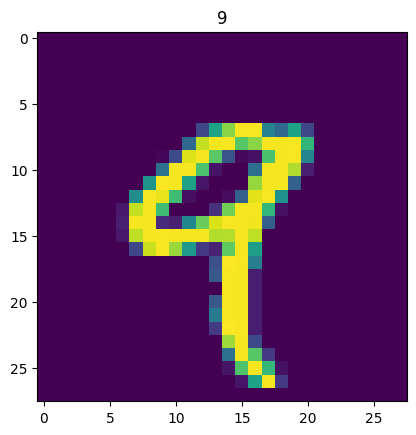

In [3]:
plt.imshow(X_train[4])
plt.title(y_train[4])
X_train[0].shape

<function matplotlib.pyplot.show(close=None, block=None)>

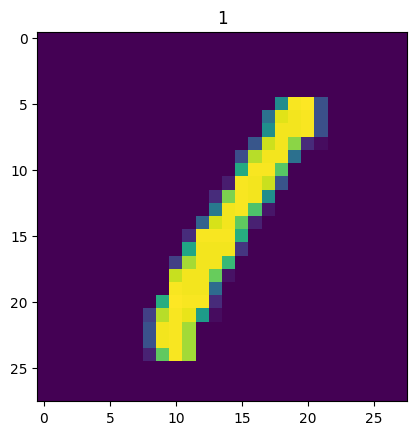

In [4]:
class_name=["0","1","2","3","4","5","6","7","8","9"]
index=3
plt.imshow(X_train[index])
plt.title(class_name[y_train[index]])
plt.show

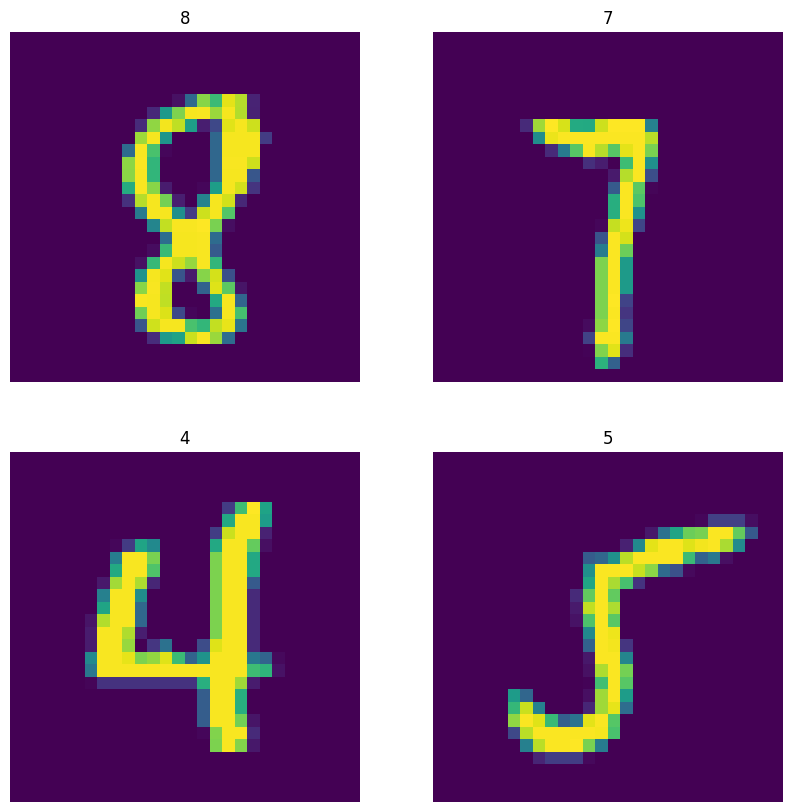

In [5]:
import random
plt.figure(figsize=(10,10))
for i in range(4):
  ax = plt.subplot(2,2,i+1)
  randindex= random.choice(range(len(X_train)))
  plt.imshow(X_train[randindex])
  plt.title(y_train[randindex])
  plt.axis(False)

In [6]:
len(X_train), len(y_train) , len(X_test), len(y_test)

(60000, 60000, 10000, 10000)

In [7]:
X_train_norm = X_train/255.0
X_test_norm = X_test/255.0
X_test_norm.min(), X_test_norm.max()

(np.float64(0.0), np.float64(1.0))

In [8]:
from tensorflow.keras.layers import Dense,Conv2D,MaxPooling2D, Activation,Flatten
from tensorflow.keras import Sequential
from tensorflow.keras import  optimizers, losses, metrics

tf.random.set_seed(42)
model11 =  tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(10,activation="softmax")
])

model11.compile(loss=tf.keras.losses.CategoricalCrossentropy(),
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])
history = model11.fit(X_train, tf.one_hot(y_train, depth=10), epochs=10,
            validation_data=(X_test, tf.one_hot(y_test, depth=10)))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.1134 - loss: 2.3871 - val_accuracy: 0.1162 - val_loss: 2.2948
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.2103 - loss: 1.9855 - val_accuracy: 0.2525 - val_loss: 1.8517
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.2617 - loss: 1.8055 - val_accuracy: 0.2834 - val_loss: 1.7755
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.2777 - loss: 1.7622 - val_accuracy: 0.2700 - val_loss: 1.7837
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.2856 - loss: 1.7483 - val_accuracy: 0.2917 - val_loss: 1.7557
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.2887 - loss: 1.7381 - val_accuracy: 0.2897 - val_loss: 1.7510
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.2916 - loss: 1.7335 - val_accuracy: 0.3014 - val_loss: 1.7509
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.2965 - loss: 1.7254 -

create the model

In [9]:
model11.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         3,140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │            50 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,632 (37.63 KB)

 Trainable params: 3,210 (12.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,422 (25.09 KB)

In [10]:
tf.random.set_seed(42)
model12 = tf.keras.Sequential([
    tf.keras.Input(shape=(28,28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model12.compile(loss=tf.keras.losses.categorical_crossentropy,
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])
history1 = model12.fit(X_train_norm, tf.one_hot(y_train, depth=10), epochs=10,
            validation_data=(X_test_norm, tf.one_hot(y_test, depth=10)))


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9298 - loss: 0.2429 - val_accuracy: 0.9643 - val_loss: 0.1230
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9699 - loss: 0.1010 - val_accuracy: 0.9721 - val_loss: 0.0933
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9790 - loss: 0.0687 - val_accuracy: 0.9747 - val_loss: 0.0840
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9849 - loss: 0.0500 - val_accuracy: 0.9742 - val_loss: 0.0857
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9880 - loss: 0.0380 - val_accuracy: 0.9783 - val_loss: 0.0809
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9902 - loss: 0.0307 - val_accuracy: 0.9760 - val_loss: 0.0915
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9910 - loss: 0.0265 - val_accuracy: 0.9769 - val_loss: 0.1004
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9929 - loss: 0.0217 - 

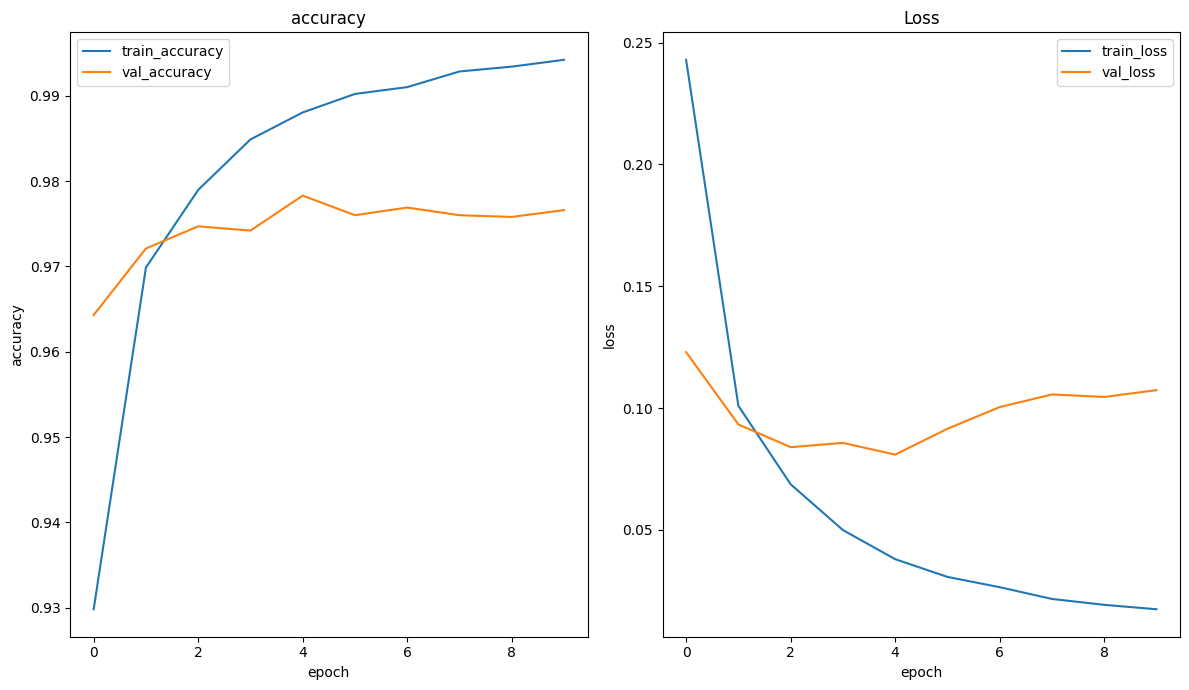

In [11]:
from prompt_toolkit.shortcuts.progress_bar import Label
def plot_histort(history):
  df = pd.DataFrame(history.history)
  epoch = range(len(df["loss"]))
  fig ,(ax1, ax2) = plt.subplots(1,2,figsize=(12,7))
  ax1.plot(epoch, df['accuracy'], label="train_accuracy")
  ax1.plot(epoch, df['val_accuracy'], label="val_accuracy")
  ax1.set_xlabel("epoch")
  ax1.set_ylabel("accuracy")
  ax1.set_title("accuracy")
  ax1.legend()
  ax2.plot(epoch, df['loss'], label="train_loss")
  ax2.plot(epoch, df['val_loss'], label="val_loss")
  ax2.set_xlabel("epoch")
  ax2.set_ylabel("loss")
  ax2.set_title("Loss")
  ax2.legend()
  plt.tight_layout()
  plt.show()
plot_histort(history1)

In [12]:
model12.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,160 (1.25 MB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,774 (854.59 KB)

In [13]:
model12.evaluate(X_test_norm, tf.one_hot(y_test, depth=10))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9766 - loss: 0.1074


[0.10737751424312592, 0.9765999913215637]

<class 'PIL.PngImagePlugin.PngImageFile'>
L
(28, 28)


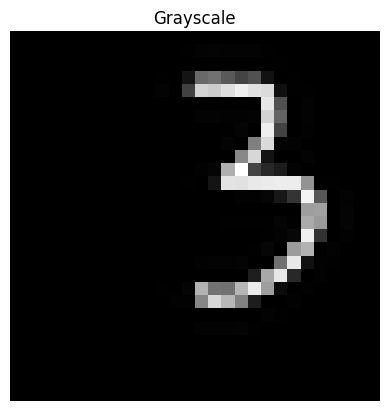

In [27]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
img = Image.open("4.png")
print(type(img))
print(img.mode)
print(img.size)
plt.imshow(img, cmap="gray")
plt.title("Grayscale")
plt.axis("off")
plt.show()

In [28]:
img = np.array(img, dtype=np.float32)
print(type(img))
print(img.shape)
print(img.dtype)
print(img.min(), img.max())

<class 'numpy.ndarray'>
(28, 28)
float32
0.0 232.0


In [29]:
img = img / 255.0

In [30]:
print(img.min(), img.max())

0.0 0.9098039


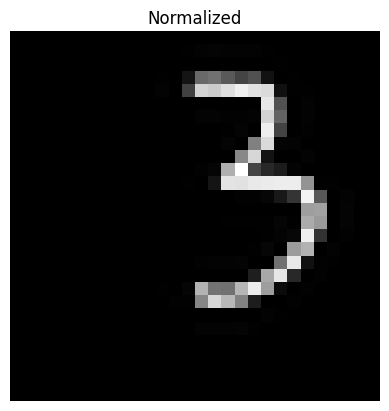

In [31]:
plt.imshow(img, cmap="gray")
plt.title("Normalized")
plt.axis("off")
plt.show()

In [32]:
img = np.expand_dims(img, axis=0)
print(img.shape)

(1, 28, 28)


In [33]:
prediction = model12.predict(img, verbose=0)

print(prediction)
print("Digit:", np.argmax(prediction))
print("Confidence:", np.max(prediction))
print(type(img))
print(img.shape)
print(img.dtype)
print(img.min(), img.max())

[[5.68509614e-03 1.42348865e-02 9.47782755e-01 2.51154192e-02
  1.57037622e-03 1.77667069e-04 5.03925560e-03 4.76004534e-05
  1.39648633e-04 2.07469348e-04]]
Digit: 2
Confidence: 0.94778275
<class 'numpy.ndarray'>
(1, 28, 28)
float32
0.0 0.9098039


In [34]:
import tensorflow as tf

model12.save("my_model.keras")
